# Лабораторная работа: Бинарная классификация факта ДТП на основе данных о дорожном трафике

**Курс:** Машинное обучение и анализ данных  

---

## Источник данных

Датасет: **[Synthetic Traffic Benchmark](https://www.kaggle.com/datasets/razanihababdellatif/emergency-dispatch-and-traffic-physics-dataset)** (синтетический бенчмарк дорожного трафика)  
Платформа: [Kaggle](https://www.kaggle.com/)  

> Датасет содержит ~200 000 записей о дорожных событиях, включающих информацию о времени, типе дороги, погодных условиях, видимости, характеристиках водителя и транспортного средства, а также сведения о произошедших ДТП (факт аварии, тип столкновения, тяжесть, время реагирования и т.д.).

In [1]:
# Базовые библиотеки
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# Визуализация
import matplotlib.pyplot as plt
import seaborn as sns

# Предобработка данных
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Модели
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

# Метрики
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    ConfusionMatrixDisplay, RocCurveDisplay
)

# Настройки отображения
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

RANDOM_STATE = 42

## 0. Постановка задачи

### Описание предметной области

В датасете собраны наблюдения за дорожным трафиком: для каждой записи известны контекстные условия (время суток, день недели, праздник), характеристики дороги (тип зоны, тип дороги, тип перекрёстка, ограничение скорости), погодные и визуальные условия (погода, состояние покрытия, видимость), параметры водителя и автомобиля (тип ТС, возраст водителя, стаж, возраст автомобиля), а также текущая скорость и индекс загруженности. Для части записей зафиксирован факт ДТП и его последствия.

### Формулировка задачи

**Тип задачи:** бинарная классификация.

**Целевая переменная:** `Accident_Occurred` ∈ {0, 1}
- `0` — ДТП не произошло;
- `1` — ДТП произошло.

**Признаки (предикторы):** все переменные, известные **в момент наблюдения до события**:
- временные: `Hour`, `Month`, `Day_of_Week`, `Time_of_Day`, `Is_Holiday`;
- дорожные: `Area_Type`, `Road_Type`, `Intersection_Type`, `Speed_Limit_kmh`;
- условия: `Weather`, `Road_Condition`, `Visibility_m`, `Congestion_Index`;
- водитель/ТС: `Vehicle_Type`, `Driver_Age`, `Driver_Experience_yrs`, `Vehicle_Age_yrs`;
- текущая динамика: `Recorded_Speed_kmh`.

**Исключаемые признаки (утечка данных / пост-фактум информация):**
`Collision_Type`, `Vehicles_Involved`, `Accident_Severity`, `Dispatch_Priority`, `Actual_Response_Time_min`, `Road_Closure_Duration_min`, `Baseline_Expected_Response_Time_min`, `Record_ID`, `Timestamp`, `Date`.

Причина: эти признаки становятся известны только *после* аварии и/или являются её прямыми следствиями — их использование привело бы к «протеканию» целевой переменной в признаки и завышенным, но бесполезным на практике метрикам.

### Прикладная цель

Построить модель, которая по условиям движения и характеристикам участника предсказывает вероятность ДТП. Это позволит:
- выявлять «опасные» комбинации условий (погода × видимость × скорость × тип дороги);
- приоритизировать профилактические меры и маршруты патрулирования;
- сравнить несколько классификаторов и подобрать оптимальную сложность модели (число соседей в kNN).

### Метрики качества

Из-за ожидаемой несбалансированности классов (ДТП — редкое событие) основной метрикой выбираем **F1-score** для положительного класса и **ROC-AUC**, вспомогательно — accuracy и матрицу рассогласования. Разбиение train/test — стратифицированное (`stratify=y`), чтобы сохранить долю классов.

### План работы

1. Загрузка и первичный осмотр данных.
2. Разбиение на обучающую и тестовую выборки.
3. Разведочный анализ (EDA): описательные статистики, распределения, корреляционная матрица, интерпретация.
4. Обработка выбросов.
5. Обработка пропущенных значений.
6. Кодирование категориальных признаков.
7. Нормализация числовых признаков (обязательна для kNN).
8. Обучение kNN-классификатора (обоснование выбора метода).
9. Оценка на train/test, матрица рассогласования, подбор гиперпараметра `k`.
10. Сравнение с другими классификаторами (LogisticRegression, RandomForest).
11. Борьба с несбалансированностью классов.
12. Отбор признаков / удаление коррелированных переменных.
13. Выводы.

## 1. Загрузка данных

In [2]:
url = "https://raw.githubusercontent.com/Svetlana-plv/Machine_Learning/refs/heads/main/synthetic_traffic_benchmark_200k.csv"
data_raw = pd.read_csv(url)
print(f"Размер датасета: {data_raw.shape[0]} строк, {data_raw.shape[1]} столбцов")

Размер датасета: 200000 строк, 29 столбцов


### 1.1. Проверка корректности чтения данных

Прежде чем приступать к анализу, необходимо убедиться, что датасет прочитан полностью и без искажений.

In [3]:
# Проверка корректности чтения
print("Тип объекта:", type(data_raw))
print("Размерность (строки, столбцы):", data_raw.shape)

Тип объекта: <class 'pandas.core.frame.DataFrame'>
Размерность (строки, столбцы): (200000, 29)


In [4]:
# Первые строки таблицы
display(data_raw.head())

# Случайная выборка — чтобы убедиться, что данные не отсортированы и читаются целиком
display(data_raw.sample(5, random_state=RANDOM_STATE))

,Record_ID,Timestamp,Date,Hour,Month,Day_of_Week,Time_of_Day,Is_Holiday,Area_Type,Road_Type,Intersection_Type,Speed_Limit_kmh,Weather,Road_Condition,Visibility_m,Congestion_Index,Vehicle_Type,Driver_Age,Driver_Experience_yrs,Vehicle_Age_yrs,Recorded_Speed_kmh,Baseline_Expected_Response_Time_min,Accident_Occurred,Collision_Type,Vehicles_Involved,Accident_Severity,Dispatch_Priority,Actual_Response_Time_min,Road_Closure_Duration_min
0,REC_0000000,2024-03-14 17:35:06.841829282,2024-03-14,17,3,Thursday,Evening Peak,0,Urban,Interstate,NaN,90,Clear,Dry,10905.0,100.0,SUV,40.0,16.0,7.2,49.0,6.2,0,NaN,0,No Accident,NaN,0.0,0.0
1,REC_0000001,2023-05-25 08:10:56.398060108,2023-05-25,8,5,Thursday,Morning Peak,0,Suburban,Interstate,NaN,100,Clear,Dry,12220.6,100.0,Sedan,48.0,26.0,9.4,70.1,15.0,0,NaN,0,No Accident,NaN,0.0,0.0
2,REC_0000002,2023-11-07 08:25:17.721608262,2023-11-07,8,11,Tuesday,Morning Peak,0,Suburban,Interstate,NaN,100,Clear,Dry,11302.4,100.0,Sedan,37.0,13.3,2.9,71.9,14.6,0,NaN,0,No Accident,NaN,0.0,0.0
3,REC_0000003,2024-07-24 09:30:00.947374674,2024-07-24,9,7,Wednesday,Morning Peak,0,Suburban,Collector,NaN,50,Clear,Dry,8641.9,50.0,SUV,48.0,12.2,4.4,58.7,13.2,0,NaN,0,No Accident,NaN,0.0,0.0
4,REC_0000004,2024-04-03 09:34:07.316651267,2024-04-03,9,4,Wednesday,Morning Peak,0,Urban,Local,T-Junction,30,Rain,Wet,3072.2,78.2,SUV,32.0,12.4,1.8,25.4,7.8,0,NaN,0,No Accident,NaN,0.0,0.0


,Record_ID,Timestamp,Date,Hour,Month,Day_of_Week,Time_of_Day,Is_Holiday,Area_Type,Road_Type,Intersection_Type,Speed_Limit_kmh,Weather,Road_Condition,Visibility_m,Congestion_Index,Vehicle_Type,Driver_Age,Driver_Experience_yrs,Vehicle_Age_yrs,Recorded_Speed_kmh,Baseline_Expected_Response_Time_min,Accident_Occurred,Collision_Type,Vehicles_Involved,Accident_Severity,Dispatch_Priority,Actual_Response_Time_min,Road_Closure_Duration_min
119737,REC_0119737,2024-03-26 01:22:38.583062081,2024-03-26,1,3,Tuesday,Night,0,Rural,Interstate,NaN,120,Rain,Wet,1984.1,27.2,SUV,28.0,0.4,1.6,110.7,21.3,0,NaN,0,No Accident,NaN,0.0,0.0
72272,REC_0072272,2025-01-23 18:44:13.669805807,2025-01-23,18,1,Thursday,Evening Peak,0,Rural,Arterial,4-Way,80,Clear,Dry,9021.6,39.9,SUV,16.0,0.0,22.4,95.1,23.5,0,NaN,0,No Accident,NaN,0.0,0.0
158154,REC_0158154,2024-01-02 19:39:02.727484095,2024-01-02,19,1,Tuesday,Evening Peak,0,Suburban,Collector,T-Junction,50,Clear,Dry,11414.0,63.4,SUV,35.0,4.3,1.3,55.1,14.0,0,NaN,0,No Accident,NaN,0.0,0.0
65426,REC_0065426,2025-02-26 07:51:25.145217268,2025-02-26,7,2,Wednesday,Morning Peak,0,Suburban,Local,T-Junction,30,Fog,Dry,223.5,40.0,Sedan,36.0,9.8,9.0,24.2,11.9,1,Side-Impact,2,Moderate,Medium,24.1,189.3
30074,REC_0030074,2025-05-18 18:07:08.972592121,2025-05-18,18,5,Sunday,Evening Peak,0,Urban,Collector,4-Way,40,Clear,Dry,8947.0,57.7,Sedan,39.0,23.0,5.0,46.3,8.8,0,NaN,0,No Accident,NaN,0.0,0.0


In [5]:
# Проверка на полностью пустые строки/столбцы
print("Полностью пустых строк:", data_raw.isna().all(axis=1).sum())
print("Полностью пустых столбцов:", data_raw.isna().all(axis=0).sum())

# Проверка типов
print("\nТипы данных по столбцам:")
print(data_raw.dtypes.value_counts())

Полностью пустых строк: 0
Полностью пустых столбцов: 0

Типы данных по столбцам:
object     14
float64     9
int64       6
Name: count, dtype: int64


### 1.2. Сводка по каждому столбцу

In [6]:
data_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 29 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   Record_ID                            200000 non-null  object 
 1   Timestamp                            200000 non-null  object 
 2   Date                                 200000 non-null  object 
 3   Hour                                 200000 non-null  int64  
 4   Month                                200000 non-null  int64  
 5   Day_of_Week                          200000 non-null  object 
 6   Time_of_Day                          200000 non-null  object 
 7   Is_Holiday                           200000 non-null  int64  
 8   Area_Type                            200000 non-null  object 
 9   Road_Type                            200000 non-null  object 
 10  Intersection_Type                    131481 non-null  object 
 11  Speed_Limit_k


**Описание столбцов:**

- `Record_ID` — уникальный идентификатор записи
- `Timestamp` — полная дата-время события
- `Date` — дата события
- `Hour` — час суток (0–23)
- `Month` — месяц года (1–12)
- `Day_of_Week` — день недели
- `Time_of_Day` — обобщённая часть суток (Morning Peak / Midday / Evening Peak / Night)
- `Is_Holiday` — флаг праздничного дня (0/1)
- `Area_Type` — тип зоны (Urban / Rural / Suburban)
- `Road_Type` — тип дороги
- `Intersection_Type` — тип перекрёстка
- `Speed_Limit_kmh` — разрешённое ограничение скорости, км/ч
- `Weather` — погодные условия
- `Road_Condition` — состояние дорожного покрытия
- `Visibility_m` — видимость в метрах
- `Congestion_Index` — индекс загруженности дороги
- `Vehicle_Type` — тип транспортного средства
- `Driver_Age` — возраст водителя, лет
- `Driver_Experience_yrs` — стаж вождения, лет
- `Vehicle_Age_yrs` — возраст автомобиля, лет
- `Recorded_Speed_kmh` — фактически зафиксированная скорость, км/ч
- `Baseline_Expected_Response_Time_min` — ожидаемое время реакции служб (пост-фактум)
- `Accident_Occurred` — факт ДТП (0 — не произошло, 1 — произошло) 
- `Collision_Type` — тип столкновения (пост-фактум)
- `Vehicles_Involved` — число участников ДТП (пост-фактум)
- `Accident_Severity` — тяжесть ДТП (пост-фактум)
- `Dispatch_Priority` — приоритет диспетчера (пост-фактум)
- `Actual_Response_Time_min` — фактическое время реакции служб (пост-фактум)
- `Road_Closure_Duration_min` — длительность перекрытия дороги (пост-фактум)

**Приведение типов категориальных признаков:**
 
Разделим все столбцы датасета по типам:

- **Целевой признак:** `Accident_Occurred` — бинарный (0/1).
- **Идентификаторы (не признаки):** `Record_ID` — уникальный ID записи.
- **Технические / служебные (не признаки):** `Timestamp`, `Date` — дублируют информацию о времени из `Hour`, `Month`, `Day_of_Week`; будут исключены.
- **Пост-фактум (утечка данных, будут исключены):** `Collision_Type`, `Vehicles_Involved`, `Accident_Severity`, `Dispatch_Priority`, `Actual_Response_Time_min`, `Road_Closure_Duration_min`, `Baseline_Expected_Response_Time_min` — становятся известны только после ДТП.
- **Бинарные:** `Is_Holiday` (0/1).
- **Категориальные (номинальные):** `Day_of_Week`, `Time_of_Day`, `Area_Type`, `Road_Type`, `Intersection_Type`, `Weather`, `Road_Condition`, `Vehicle_Type`.
- **Количественные:** `Hour`, `Month`, `Speed_Limit_kmh`, `Visibility_m`, `Congestion_Index`, `Driver_Age`, `Driver_Experience_yrs`, `Vehicle_Age_yrs`, `Recorded_Speed_kmh` — числовые признаки с физическим смыслом (час, км/ч, метры, годы и т.д.).

Категориальные столбцы приведём к специальному типу `category` — это экономит память (хранятся коды, а не строки в каждой строке) и ускоряет группировку/фильтрацию.

In [7]:
# Номинальные категориальные признаки (мало уникальных значений, строки)
categorical_cols = [
    'Day_of_Week',
    'Time_of_Day',
    'Area_Type',
    'Road_Type',
    'Intersection_Type',
    'Weather',
    'Road_Condition',
    'Vehicle_Type',
]

for col in categorical_cols:
    data_raw[col] = data_raw[col].astype('category')

# Полный набор значений (категорий) для каждого категориального столбца
print("Набор значений категориальных признаков:\n")
for col in categorical_cols:
    cats = data_raw[col].cat.categories.tolist()
    print(f"{col} ({len(cats)} уровн.):")
    print(f"  {cats}\n")


Набор значений категориальных признаков:

Day_of_Week (7 уровн.):
  ['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']

Time_of_Day (4 уровн.):
  ['Evening Peak', 'Midday', 'Morning Peak', 'Night']

Area_Type (3 уровн.):
  ['Rural', 'Suburban', 'Urban']

Road_Type (4 уровн.):
  ['Arterial', 'Collector', 'Interstate', 'Local']

Intersection_Type (3 уровн.):
  ['4-Way', 'Roundabout', 'T-Junction']

Weather (7 уровн.):
  [' RAIN', 'Clear', 'Fog', 'Rain', 'Rain ', 'Snow', 'rain']

Road_Condition (5 уровн.):
  ['Dry', 'Icy', 'Snowy', 'Standing Water', 'Wet']

Vehicle_Type (5 уровн.):
  ['Bus', 'Motorcycle', 'SUV', 'Sedan', 'Truck']



**Анализ значений категориальных признаков и очистка «грязных» категорий:**

Из вывода видно, что большинство признаков чистые, но **`Weather` содержит 7 уровней вместо ожидаемых 4**:

`[' RAIN', 'Clear', 'Fog', 'Rain', 'Rain ', 'Snow', 'rain']`

**Причина** — разный регистр и лишние пробелы. По сути это один и тот же класс `Rain`, записанный четырьмя способами: `' RAIN'`, `'Rain'`, `'Rain '`, `'rain'`. 

**Решение:** нормализовать `Weather` — убрать пробелы (`.str.strip()`) и привести к единому регистру (`.str.lower()`), затем снова привести к `category`.


In [8]:
# Нормализация Weather: убираем пробелы и приводим к нижнему регистру
# (столбец уже имеет тип category — конвертируем в строку, чистим, возвращаем category)
data_raw['Weather'] = (
    data_raw['Weather']
    .astype(str)
    .str.strip()
    .str.lower()
    .str.capitalize()  
    .astype('category')
)

# Проверка результата
print("Weather после нормализации:")
print(f"  уровней: {data_raw['Weather'].cat.categories.size}")
print(f"  значения: {data_raw['Weather'].cat.categories.tolist()}")

Weather после нормализации:
  уровней: 4
  значения: ['Clear', 'Fog', 'Rain', 'Snow']


**Анализ пропусков в `Intersection_Type`**  
Столбец `Intersection_Type` содержит ~34% пропусков (`None`). Прежде чем заполнять их, проверим гипотезу: **не связаны ли пропуски с тем, что на данном участке перекрёстка физически нет** (например, на магистрали `Interstate`).

In [9]:
# Гипотеза: NaN в Intersection_Type связан с типом дороги
print("Доля пропусков по Road_Type:")
print(
    data_raw.groupby('Road_Type')['Intersection_Type']
    .apply(lambda s: s.isna().mean())
    .sort_values(ascending=False)
)

Доля пропусков по Road_Type:
Road_Type
Interstate    1.000000
Local         0.399200
Collector     0.201254
Arterial      0.000000
Name: Intersection_Type, dtype: float64


- На магистралях (`Interstate`) перекрёстков не бывает физически — поэтому там 100% пропусков.
- На артериальных улицах (`Arterial`) перекрёстки есть всегда — 0% пропусков.
- `Local` и `Collector` занимают промежуточное положение — на них перекрёстки бывают не всегда.

Значит, `None` в `Intersection_Type` — это **семантический пропуск**, означающий «перекрёстка нет», а не потеря данных. Заполним его явной категорией `"No Intersection"`, чтобы сохранить эту информацию для модели, а не искажать её модой.


In [10]:
data_raw['Intersection_Type'] = (
    data_raw['Intersection_Type']
    .astype(object)              # временно снять category
    .fillna('No Intersection')   # теперь можно заполнять строкой
    .astype('category')          # снова сделать category
)

# Проверка
print("Intersection_Type после заполнения:")
print(f"  уровней: {data_raw['Intersection_Type'].cat.categories.size}")
print(f"  значения: {data_raw['Intersection_Type'].cat.categories.tolist()}")
print(f"\nРаспределение:")
print(data_raw['Intersection_Type'].value_counts(dropna=False))

Intersection_Type после заполнения:
  уровней: 4
  значения: ['4-Way', 'No Intersection', 'Roundabout', 'T-Junction']

Распределение:
Intersection_Type
No Intersection    68519
4-Way              66164
T-Junction         51931
Roundabout         13386
Name: count, dtype: int64


### 1.3. Проверка наличия дублирующихся строк


In [11]:
counts = data_raw['Record_ID'].value_counts()
print(counts[counts > 1])


Record_ID
REC_0002958    2
REC_0086356    2
REC_0161587    2
REC_0145781    2
REC_0193705    2
              ..
REC_0184830    2
REC_0152045    2
REC_0049820    2
REC_0118300    2
REC_0143052    2
Name: count, Length: 597, dtype: int64


In [12]:
# Дубли по всем столбцам, кроме Record_ID
cols = [c for c in data_raw.columns if c != 'Record_ID']
full_dups = data_raw.duplicated(subset=cols, keep=False)
print("Полных дублей (без учёта ID):", full_dups.sum())

# Посмотреть на примеры
display(data_raw[full_dups].sort_values(cols).head(10))

# Дубли только по Record_ID
id_dups = data_raw['Record_ID'].duplicated(keep=False)
print("Строк с повторяющимся Record_ID:", id_dups.sum())

# Пересечение: и ID повторяется, и строка полностью совпадает
print("Совпадает и ID, и все признаки:", (full_dups & id_dups).sum())


Полных дублей (без учёта ID): 1194


,Record_ID,Timestamp,Date,Hour,Month,Day_of_Week,Time_of_Day,Is_Holiday,Area_Type,Road_Type,Intersection_Type,Speed_Limit_kmh,Weather,Road_Condition,Visibility_m,Congestion_Index,Vehicle_Type,Driver_Age,Driver_Experience_yrs,Vehicle_Age_yrs,Recorded_Speed_kmh,Baseline_Expected_Response_Time_min,Accident_Occurred,Collision_Type,Vehicles_Involved,Accident_Severity,Dispatch_Priority,Actual_Response_Time_min,Road_Closure_Duration_min
91211,REC_0091211,2022-01-10 17:48:57.501033079,2022-01-10,17,1,Monday,Evening Peak,0,Rural,Interstate,No Intersection,120,Snow,Icy,1071.4,99.2,SUV,19.0,3.0,7.3,54.7,25.0,0,NaN,0,No Accident,NaN,0.0,0.0
199141,REC_0091211,2022-01-10 17:48:57.501033079,2022-01-10,17,1,Monday,Evening Peak,0,Rural,Interstate,No Intersection,120,Snow,Icy,1071.4,99.2,SUV,19.0,3.0,7.3,54.7,25.0,0,NaN,0,No Accident,NaN,0.0,0.0
109420,REC_0109420,2022-01-17 06:23:35.853323670,2022-01-17,6,1,Monday,Morning Peak,1,Rural,Arterial,4-Way,80,Fog,Wet,303.6,30.9,Truck,34.0,17.0,7.2,71.1,21.8,0,NaN,0,No Accident,NaN,0.0,0.0
199401,REC_0109420,2022-01-17 06:23:35.853323670,2022-01-17,6,1,Monday,Morning Peak,1,Rural,Arterial,4-Way,80,Fog,Wet,303.6,30.9,Truck,34.0,17.0,7.2,71.1,21.8,0,NaN,0,No Accident,NaN,0.0,0.0
90202,REC_0090202,2022-01-20 17:49:01.957910330,2022-01-20,17,1,Thursday,Evening Peak,0,Suburban,Arterial,Roundabout,60,Clear,Dry,9106.5,74.7,SUV,51.0,35.0,12.8,67.8,9.6,0,NaN,0,No Accident,NaN,0.0,0.0
199305,REC_0090202,2022-01-20 17:49:01.957910330,2022-01-20,17,1,Thursday,Evening Peak,0,Suburban,Arterial,Roundabout,60,Clear,Dry,9106.5,74.7,SUV,51.0,35.0,12.8,67.8,9.6,0,NaN,0,No Accident,NaN,0.0,0.0
29961,REC_0029961,2022-01-29 16:35:03.002375130,2022-01-29,16,1,Saturday,Evening Peak,0,Urban,Arterial,4-Way,50,Clear,Dry,6611.5,84.7,Sedan,45.0,5.2,14.3,36.9,9.0,0,NaN,0,No Accident,NaN,0.0,0.0
199590,REC_0029961,2022-01-29 16:35:03.002375130,2022-01-29,16,1,Saturday,Evening Peak,0,Urban,Arterial,4-Way,50,Clear,Dry,6611.5,84.7,Sedan,45.0,5.2,14.3,36.9,9.0,0,NaN,0,No Accident,NaN,0.0,0.0
74118,REC_0074118,2022-02-01 07:38:31.558701408,2022-02-01,7,2,Tuesday,Morning Peak,0,Suburban,Arterial,T-Junction,60,Fog,Wet,265.6,81.1,Sedan,35.0,19.0,8.9,56.1,12.8,0,NaN,0,No Accident,NaN,0.0,0.0
199257,REC_0074118,2022-02-01 07:38:31.558701408,2022-02-01,7,2,Tuesday,Morning Peak,0,Suburban,Arterial,T-Junction,60,Fog,Wet,265.6,81.1,Sedan,35.0,19.0,8.9,56.1,12.8,0,NaN,0,No Accident,NaN,0.0,0.0


Строк с повторяющимся Record_ID: 1194
Совпадает и ID, и все признаки: 1194


Избавимся от дубликатов и оставим по одному экземпляру каждого:

In [13]:
before = len(data_raw)
data_raw = data_raw.drop_duplicates(keep='first').reset_index(drop=True)
print(f"Удалено дублей: {before - len(data_raw)}")
print(f"Размер после удаления: {data_raw.shape}")

Удалено дублей: 597
Размер после удаления: (199403, 29)


In [14]:
# Проверяем, что дублей не осталось
print("Дублей по Record_ID:", data_raw['Record_ID'].duplicated().sum())
print("Полных дублей:", data_raw.duplicated().sum())

# Убеждаемся, что Record_ID теперь уникален
assert data_raw['Record_ID'].is_unique, "Остались дубли Record_ID!"
print("Record_ID уникален ✓")

Дублей по Record_ID: 0
Полных дублей: 0
Record_ID уникален ✓


**Обработка дубликатов:** В датасете обнаружено 597 пар полностью идентичных строк (1194 записи): совпадают и Record_ID, и все 28 остальных признаков. Это технические дубли, не несущие новой информации. Они удалены методом drop_duplicates(keep='first'), так как при случайном разбиении на train/test один и тот же объект мог попасть в обе выборки, что привело бы к утечке данных и завышенным метрикам качества. После удаления осталось 199 403 уникальные записи.

### 1.4. Выбор индекса таблицы

Теперь в полученном списке нет повторяющихся записей. В качестве индекса выбираем столбец `Record_ID` — уникальный идентификатор записи. Используем его
как индекс DataFrame — это удобно для идентификации строк и не влияет на
моделирование, поскольку `Record_ID` исключён из списка признаков.

In [15]:
data_raw = data_raw.set_index('Record_ID')
print("Индекс установлен:", data_raw.index.name)
print("Уникален:", data_raw.index.is_unique)

Индекс установлен: Record_ID
Уникален: True


### 1.5. Построение целевой переменной

Посмотрим на распределение целевой переменной (`Accident_Occurred`), чтобы оценить баланс классов:

In [16]:
data_raw['Accident_Occurred'].describe()

count    199403.000000
mean          0.041188
std           0.198725
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           1.000000
Name: Accident_Occurred, dtype: float64

In [17]:
print('Записей без ДТП (0): ', (data_raw['Accident_Occurred'] == 0).sum())
print('Записей с ДТП (1):   ', (data_raw['Accident_Occurred'] == 1).sum())

Записей без ДТП (0):  191190
Записей с ДТП (1):    8213


Датасет содержит подавляющее большинство записей без ДТП (класс 0) и лишь малую долю записей с произошедшими авариями (класс 1). Данные сильно несбалансированы. 

In [18]:
# Формируем целевую переменную (target)
y = data_raw['Accident_Occurred'].copy()
# Доли классов
data_raw['Accident_Occurred'].value_counts(normalize=True)

Accident_Occurred
0    0.958812
1    0.041188
Name: proportion, dtype: float64

### 1.6. Исключение лишних столбцов

Часть признаков напрямую связана с тем, что предсказывает модель (пост-фактум информация), либо не несёт полезной информации для машинного обучения. Такие столбцы необходимо исключить, чтобы избежать утечки данных (data leakage) и не завышать метрики качества.

**Утечка данных (стали известны после ДТП):**
- `Collision_Type`, `Accident_Severity` — следствия аварии;
- `Vehicles_Involved` — количество участников;
- `Dispatch_Priority`, `Actual_Response_Time_min`, `Baseline_Expected_Response_Time_min`, `Road_Closure_Duration_min` — параметры работы экстренных служб.

**Технические / служебные признаки (не несут физического смысла для модели):**
- `Timestamp`, `Date` — дублируют информацию о времени из `Hour`, `Month`, `Day_of_Week`;
- `Record_ID` — является индексом (уже убран из таблицы как столбец).


In [19]:
# 1. Признаки, являющиеся следствием аварии (утечка)
leak_columns = [
    'Collision_Type', 'Vehicles_Involved', 'Accident_Severity', 
    'Dispatch_Priority', 'Actual_Response_Time_min', 
    'Road_Closure_Duration_min', 'Baseline_Expected_Response_Time_min'
]

# 2. Технические признаки (служебные)
technical_columns = ['Timestamp', 'Date']

# Объединяем списки для удаления
columns_to_drop = leak_columns + technical_columns

# Удаляем их из датафрейма
data_clean = data_raw.drop(columns=columns_to_drop)

# Проверяем результат
print(f"Удалено столбцов: {len(columns_to_drop)}")
print(f"Размерность после удаления: {data_clean.shape}")
print("\nОставшиеся столбцы:")
print(data_clean.columns.tolist())

Удалено столбцов: 9
Размерность после удаления: (199403, 19)

Оставшиеся столбцы:
['Hour', 'Month', 'Day_of_Week', 'Time_of_Day', 'Is_Holiday', 'Area_Type', 'Road_Type', 'Intersection_Type', 'Speed_Limit_kmh', 'Weather', 'Road_Condition', 'Visibility_m', 'Congestion_Index', 'Vehicle_Type', 'Driver_Age', 'Driver_Experience_yrs', 'Vehicle_Age_yrs', 'Recorded_Speed_kmh', 'Accident_Occurred']


## 2. Разбиение на обучающую и тестовую выборки

Сформируем матрицу признаков `X`, исключив целевую переменную `Accident_Occurred`, и вектор ответов `y`.

Разбиение выполним со стратификацией (`stratify=y`), чтобы сохранить исходную пропорцию классов (~4.1% ДТП) в обеих выборках. Тестовая выборка составит 20% от всех данных.

In [20]:
# 1. Формируем X (признаки) и y (целевая переменная) из очищенных данных
X = data_clean.drop(columns=['Accident_Occurred'])
y = data_clean['Accident_Occurred']

# 2. Разбиение на train/test (20% на тест)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    stratify=y, 
    random_state=RANDOM_STATE
)

Проверим размерности полученных выборок и убедимся, что доли классов сохранились.

In [21]:
print(f"Размер X_train: {X_train.shape}")
print(f"Размер X_test:  {X_test.shape}")
print(f"\nДоля ДТП в train: {y_train.mean():.4f}")
print(f"Доля ДТП в test:  {y_test.mean():.4f}")

# Проверка, что признаки и таргет согласованы по индексам
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)
print("\nИндексы X и y согласованы ✓")

Размер X_train: (159522, 18)
Размер X_test:  (39881, 18)

Доля ДТП в train: 0.0412
Доля ДТП в test:  0.0412

Индексы X и y согласованы ✓


## 3. Визуализация и основные характеристики

### 3.1. Подготовка данных для анализа

Анализ проводится только по **обучающей** выборке. Для удобства объединим признаки с целевой переменной в один DataFrame `train_df` (`Accident_Occurred` = 1 — ДТП). Разделим признаки на числовые и категориальные.

In [22]:
train_df = X_train.assign(Accident_Occurred=y_train.values)

numeric_features = [
    'Hour', 'Month', 'Speed_Limit_kmh', 'Visibility_m',
    'Congestion_Index', 'Driver_Age', 'Driver_Experience_yrs',
    'Vehicle_Age_yrs', 'Recorded_Speed_kmh',
]
cat_features = [c for c in categorical_cols if c in X_train.columns]

print(f"Строк: {train_df.shape[0]}, колонок: {train_df.shape[1]}")
print(f"Числовых признаков: {len(numeric_features)}")
print(f"Категориальных: {len(cat_features)}")
print(f"Доля ДТП: {train_df['Accident_Occurred'].mean():.4f}")

Строк: 159522, колонок: 19
Числовых признаков: 9
Категориальных: 8
Доля ДТП: 0.0412


**Информация о категориальных признаках:**

In [23]:
train_df[categorical_cols].describe(include=['category']).T

,count,unique,top,freq
Day_of_Week,159522,7,Friday,25437
Time_of_Day,159522,4,Midday,47632
Area_Type,159522,3,Urban,64046
Road_Type,159522,4,Arterial,53962
Intersection_Type,159522,4,No Intersection,54753
Weather,159522,4,Clear,91647
Road_Condition,159522,5,Dry,94264
Vehicle_Type,159522,5,Sedan,70439


**Информация о числовых признаках:**

In [24]:
# Список числовых признаков (до удаления leak-столбцов)
numeric_cols = [
    'Hour', 'Month', 'Is_Holiday', 'Speed_Limit_kmh',
    'Visibility_m', 'Congestion_Index', 'Driver_Age',
    'Driver_Experience_yrs', 'Vehicle_Age_yrs', 'Recorded_Speed_kmh',
    'Accident_Occurred',  # для контроля (целевой)
]

train_df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Hour,159522.0,12.222396,5.507576,0.0,8.0,12.0,17.0,23.0
Month,159522.0,6.535393,3.450125,1.0,4.0,7.0,10.0,12.0
Is_Holiday,159522.0,0.032002,0.176005,0.0,0.0,0.0,0.0,1.0
Speed_Limit_kmh,159522.0,57.539336,26.383333,30.0,30.0,50.0,80.0,120.0
Visibility_m,155442.0,6454.743235,4541.058857,73.2,1734.7,7935.2,10390.1,15000.0
Congestion_Index,159522.0,55.673337,28.700488,2.2,31.6,53.7,79.2,100.0
Driver_Age,159522.0,38.344849,13.276147,16.0,29.0,38.0,47.0,85.0
Driver_Experience_yrs,156346.0,10.622521,7.804542,0.0,4.7,9.4,15.2,59.0
Vehicle_Age_yrs,159522.0,6.979261,4.771756,0.0,3.4,6.1,9.4,30.0
Recorded_Speed_kmh,159522.0,49.634279,31.844227,0.0,30.4,43.9,62.2,999.0


### 3.2. Распределение целевой переменной

Визуализируем баланс классов. Это определяет выбор метрик качества.

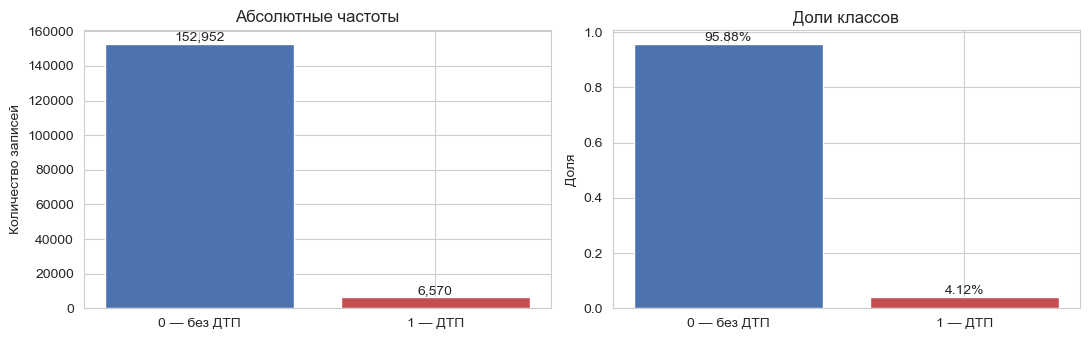

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

counts = train_df['Accident_Occurred'].value_counts().sort_index()
axes[0].bar(['0 — без ДТП', '1 — ДТП'], counts.values, color=['#4C72B0', '#C44E52'])
axes[0].set_title('Абсолютные частоты')
axes[0].set_ylabel('Количество записей')
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f'{v:,}', ha='center', va='bottom')

shares = train_df['Accident_Occurred'].value_counts(normalize=True).sort_index()
axes[1].bar(['0 — без ДТП', '1 — ДТП'], shares.values, color=['#4C72B0', '#C44E52'])
axes[1].set_title('Доли классов')
axes[1].set_ylabel('Доля')
for i, v in enumerate(shares.values):
    axes[1].text(i, v, f'{v:.2%}', ha='center', va='bottom')

plt.tight_layout()
plt.show()


### 3.3. Гистограммы числовых признаков

Гистограммы показывают форму распределения.

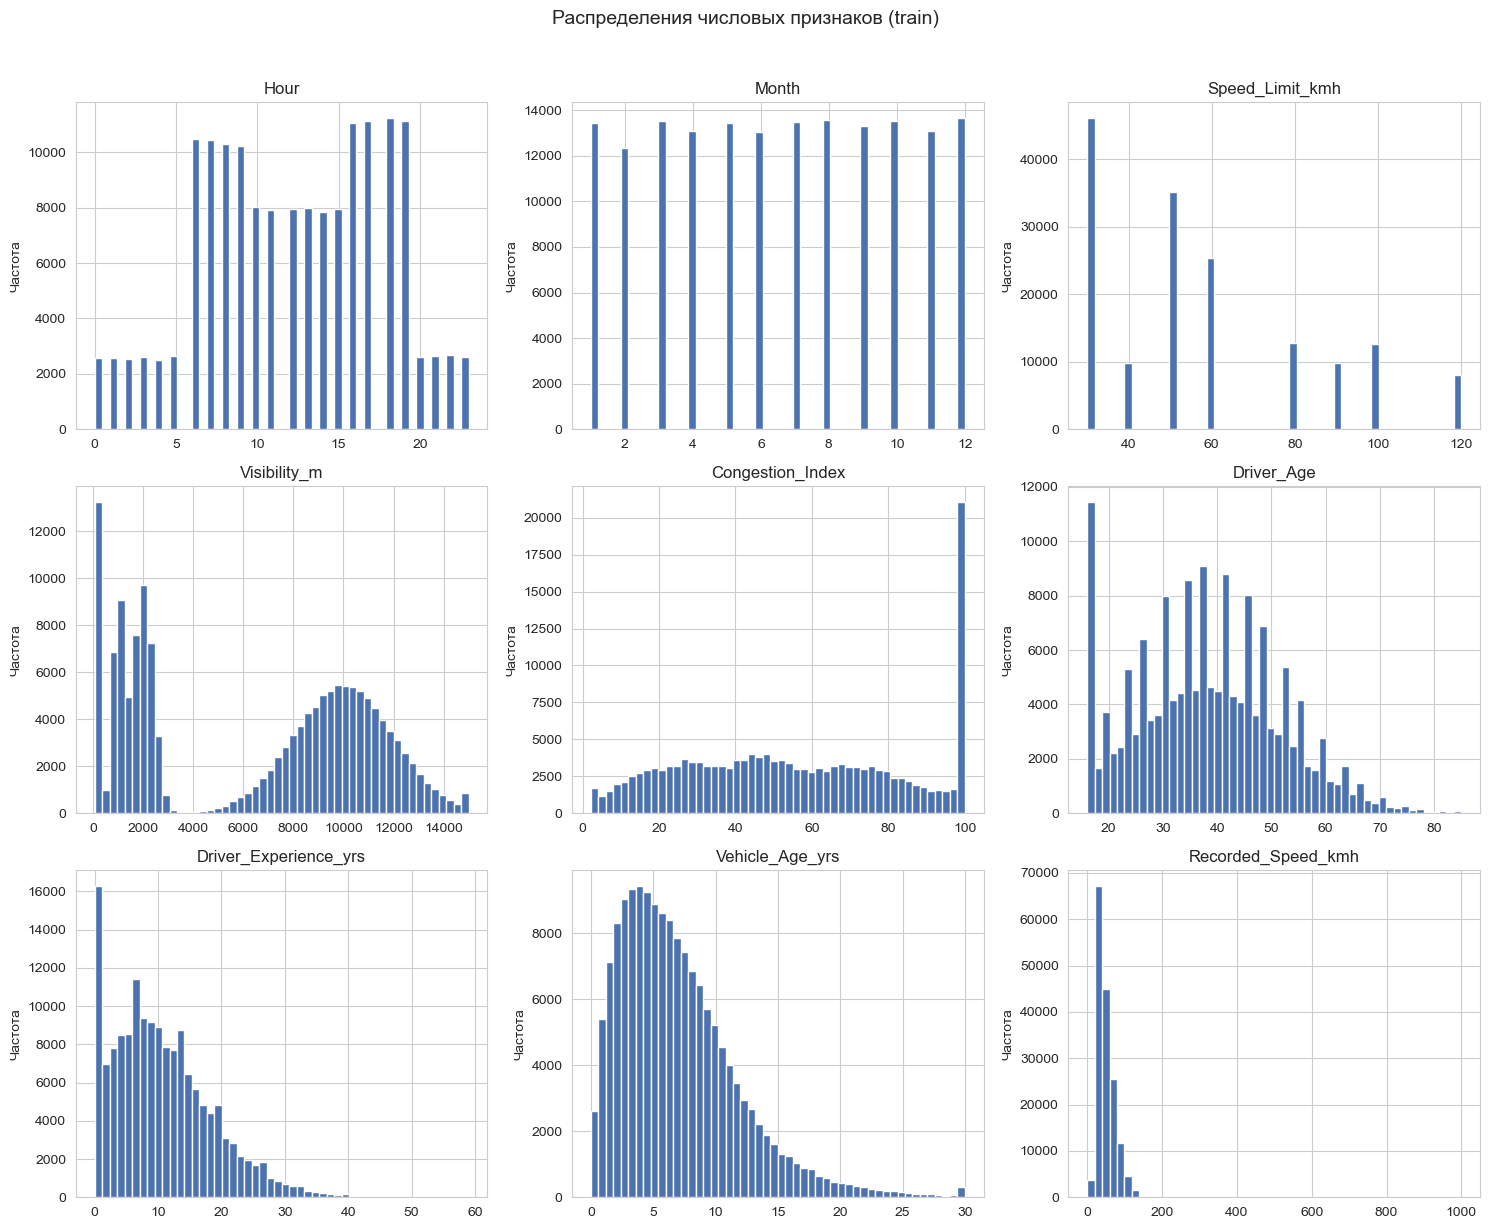

In [26]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.ravel()

for ax, col in zip(axes, numeric_features):
    ax.hist(train_df[col].dropna(), bins=50, color='#4C72B0', edgecolor='white')
    ax.set_title(col)
    ax.set_ylabel('Частота')

plt.suptitle('Распределения числовых признаков (train)', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

**`Hour`** — бимодальное распределение с пиками в утренние (7–9) и вечерние (16–19) часы: трафик фиксируется преимущественно в часы пик.

**`Month`** — практически равномерное распределение: записи сгенерированы равномерно в течение года.

**`Speed_Limit_kmh`** — дискретные «столбики» на значениях 30, 40, 50, 60, 80, 100, 120. По сути это **порядковая категория**, не непрерывный признак.

**`Visibility_m`** — двугорбое распределение: пик вблизи 0–2 км (туман, снег, дождь) и широкий пик 8–11 км (ясная погода). Середина (3–5 км) почти пуста — видимость либо плохая, либо хорошая.

**`Congestion_Index`** — почти равномерное на [0, 100], но с резким всплеском на значении 100: типичный «потолок» индекса, признак перегруженности дороги.

**`Driver_Age`** — основная масса 20–55 лет, пик 35–40. Распределение с **ярко выраженным выбросом в минимуме** (16 лет — минимально допустимый возраст) и лёгким правым хвостом.

**`Driver_Experience_yrs`** — сильный пик у 0 и быстрый спад: большинство водителей имеют небольшой стаж; длинный правый хвост до 60 лет.

**`Vehicle_Age_yrs`** — одновершинное с модой ~4 года, длинный правый хвост до 30 лет: преобладают относительно новые машины, но есть небольшой процент «старых».

**`Recorded_Speed_kmh`** — почти всё сосредоточено в диапазоне 0–100 км/ч, но есть **явные артефакты датчика** в правом хвосте (значения 400–999). Это кандидаты в выбросы

### 3.4. Boxplot числовых признаков

Boxplot наглядно показывает выбросы по правилу 1.5·IQR. Это подготовка к п. 4.

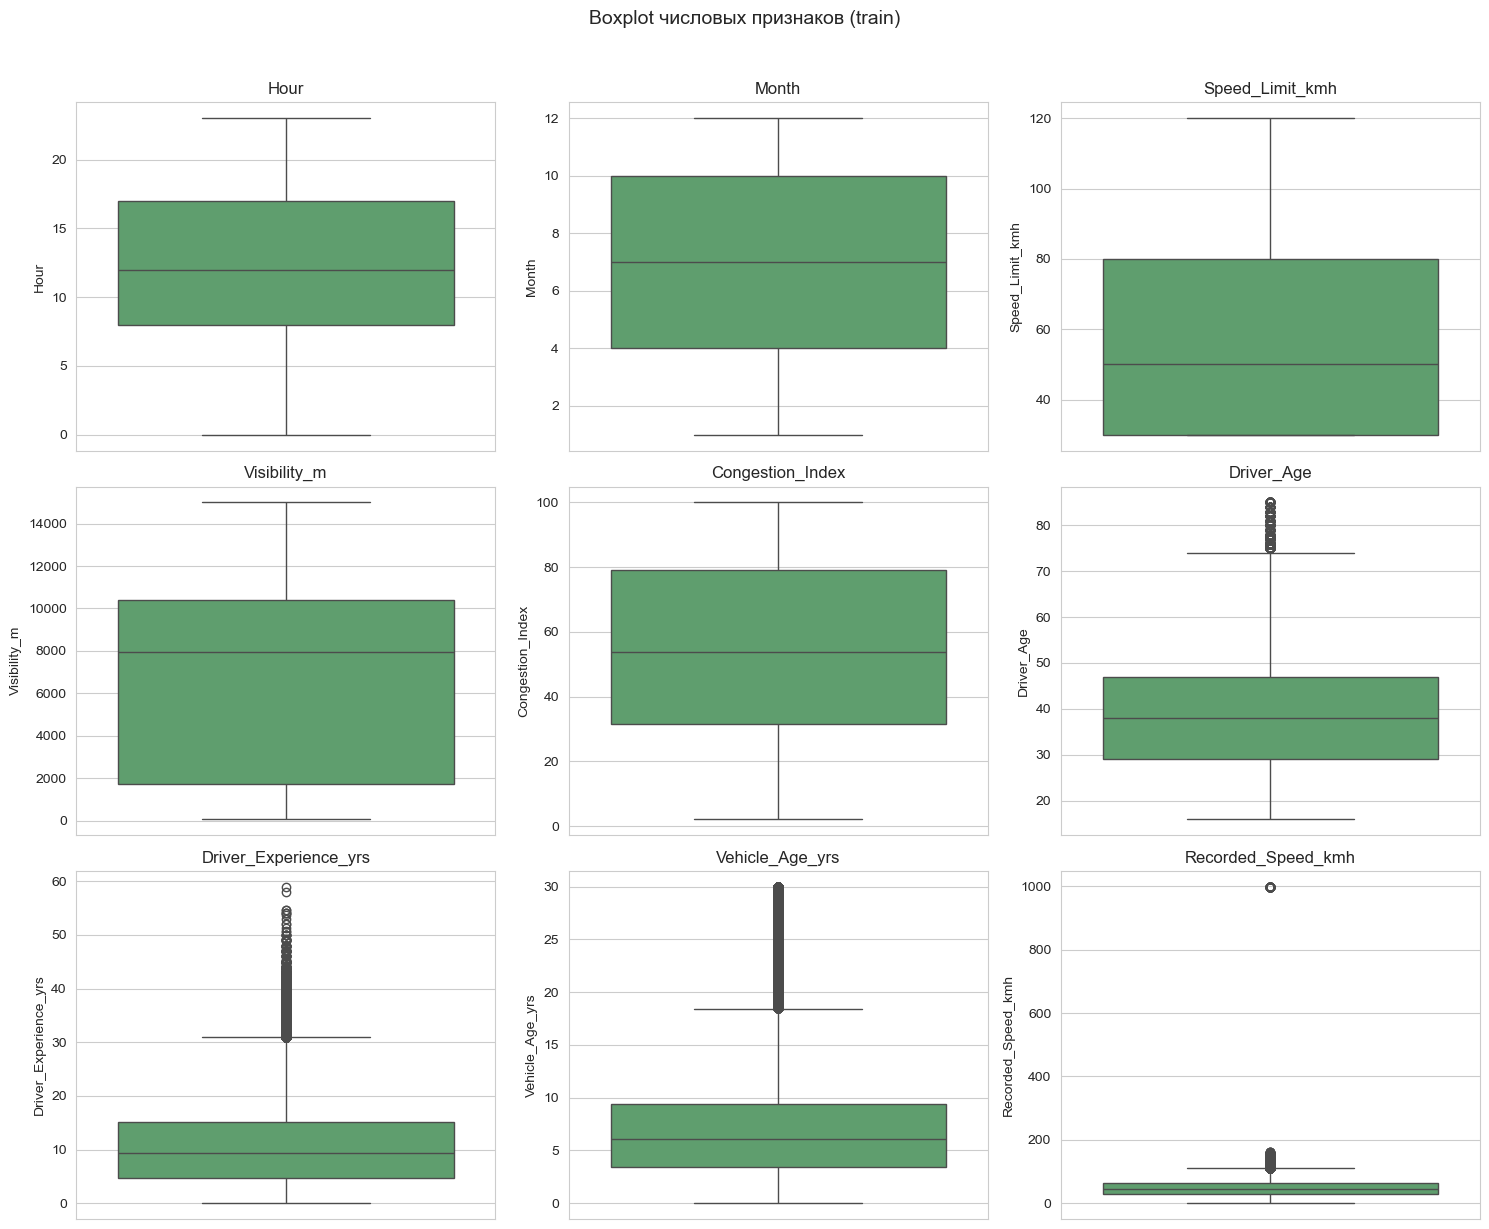

In [27]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.ravel()

for ax, col in zip(axes, numeric_features):
    sns.boxplot(y=train_df[col], ax=ax, color='#55A868')
    ax.set_title(col)

plt.suptitle('Boxplot числовых признаков (train)', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

**`Hour`, `Month`, `Speed_Limit_kmh`, `Visibility_m`, `Congestion_Index`** — выбросов нет, «усы» доходят до границ диапазона. Для `Speed_Limit_kmh` межквартильный размах широкий (30–80), что подтверждает: признак дискретный и равномерно покрывает допустимые значения.

**`Driver_Age`** — верхние «усы» до 73 лет, выше — несколько десятков точек-выбросов (74–85). Это **реальные опытные водители**, а не артефакты.

**`Driver_Experience_yrs`** — правый хвост до 31 года, затем плотная полоса выбросов 32–59 лет. Реальные значения (водители с очень большим стажем) — обрабатывать как выбросы **не нужно**.

**`Vehicle_Age_yrs`** — «усы» до ~18 лет, затем полоса выбросов 18–30 лет. Также реальные старые машины, оставляем.

**`Recorded_Speed_kmh`** — одиночное значение 999 — **явный артефакт датчика**.

**Итог:** удалению/обрезке подлежит только `Recorded_Speed_kmh`; остальные «выбросы» — реальные значения и несут полезную информацию.

### 3.5. Числовые признаки в разрезе классов

Сравним распределения числовых признаков для классов «0» и «1». Сильный сдвиг кривых ⇒ признак полезен.

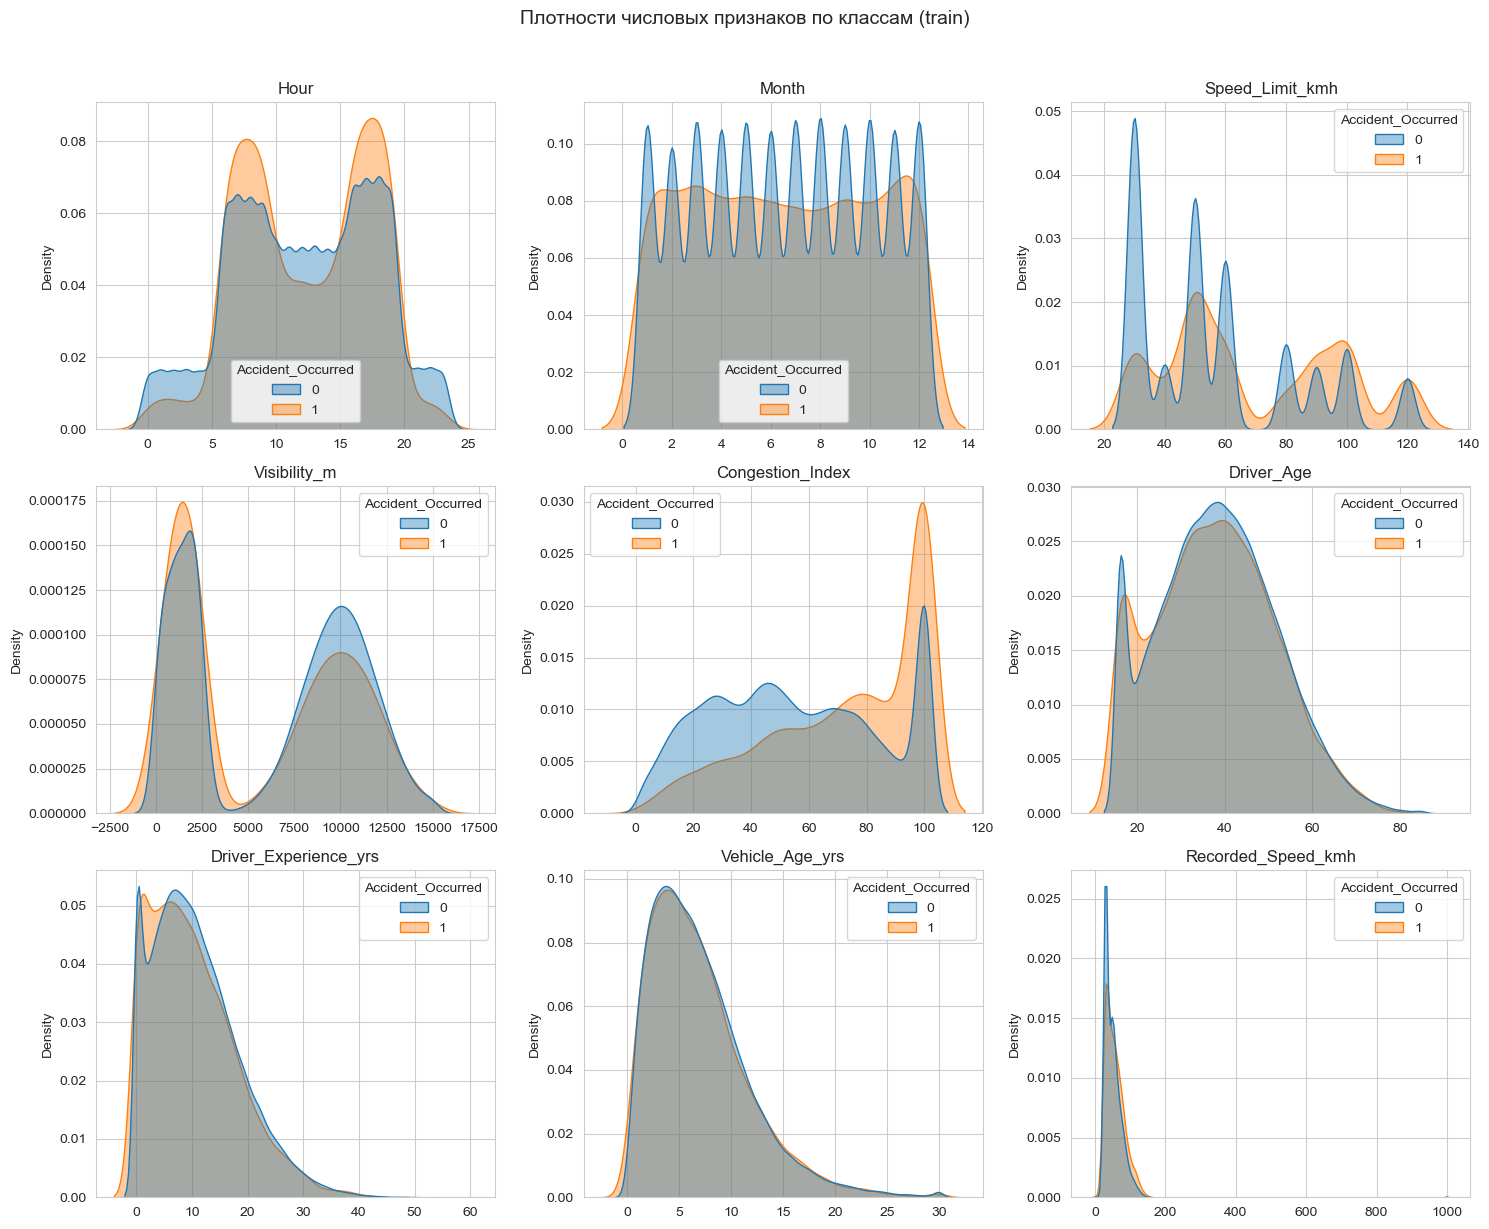

In [28]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.ravel()

for ax, col in zip(axes, numeric_features):
    sns.kdeplot(data=train_df, x=col, hue='Accident_Occurred',
                common_norm=False, fill=True, alpha=0.4, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')

plt.suptitle('Плотности числовых признаков по классам (train)', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

**Итог:** наибольший вклад в разделение классов дают **`Speed_Limit_kmh`, `Visibility_m`, `Congestion_Index`, `Recorded_Speed_kmh`**;   
слабые — `Month`, `Driver_Experience_yrs`, `Vehicle_Age_yrs`.


### 3.6. Категориальные признаки: частоты и доля ДТП

Для каждого уровня категориального признака считаем долю положительного класса. Большой разброс доли между уровнями ⇒ признак информативен.

In [29]:
fail_rate = []
for c in cat_features:
    s = train_df.groupby(c, observed=True)['Accident_Occurred'].mean()
    n = train_df[c].value_counts().reindex(s.index)
    fail_rate.append(pd.DataFrame({'признак': c, 'значение': s.index,
                                   'доля ДТП': s.values, 'кол-во': n.values}))
fail_rate = pd.concat(fail_rate, ignore_index=True)
fail_rate.style.background_gradient(subset=['доля ДТП'], cmap='Reds').format({'доля ДТП': '{:.4f}'})

,признак,значение,доля ДТП,кол-во
0,Day_of_Week,Friday,0.0451,25437
1,Day_of_Week,Monday,0.0417,25009
2,Day_of_Week,Saturday,0.0368,16732
3,Day_of_Week,Sunday,0.0300,16716
4,Day_of_Week,Thursday,0.0425,25047
5,Day_of_Week,Tuesday,0.0419,25265
6,Day_of_Week,Wednesday,0.0451,25316
7,Time_of_Day,Evening Peak,0.0515,44546
8,Time_of_Day,Midday,0.0342,47632
9,Time_of_Day,Morning Peak,0.0520,41423


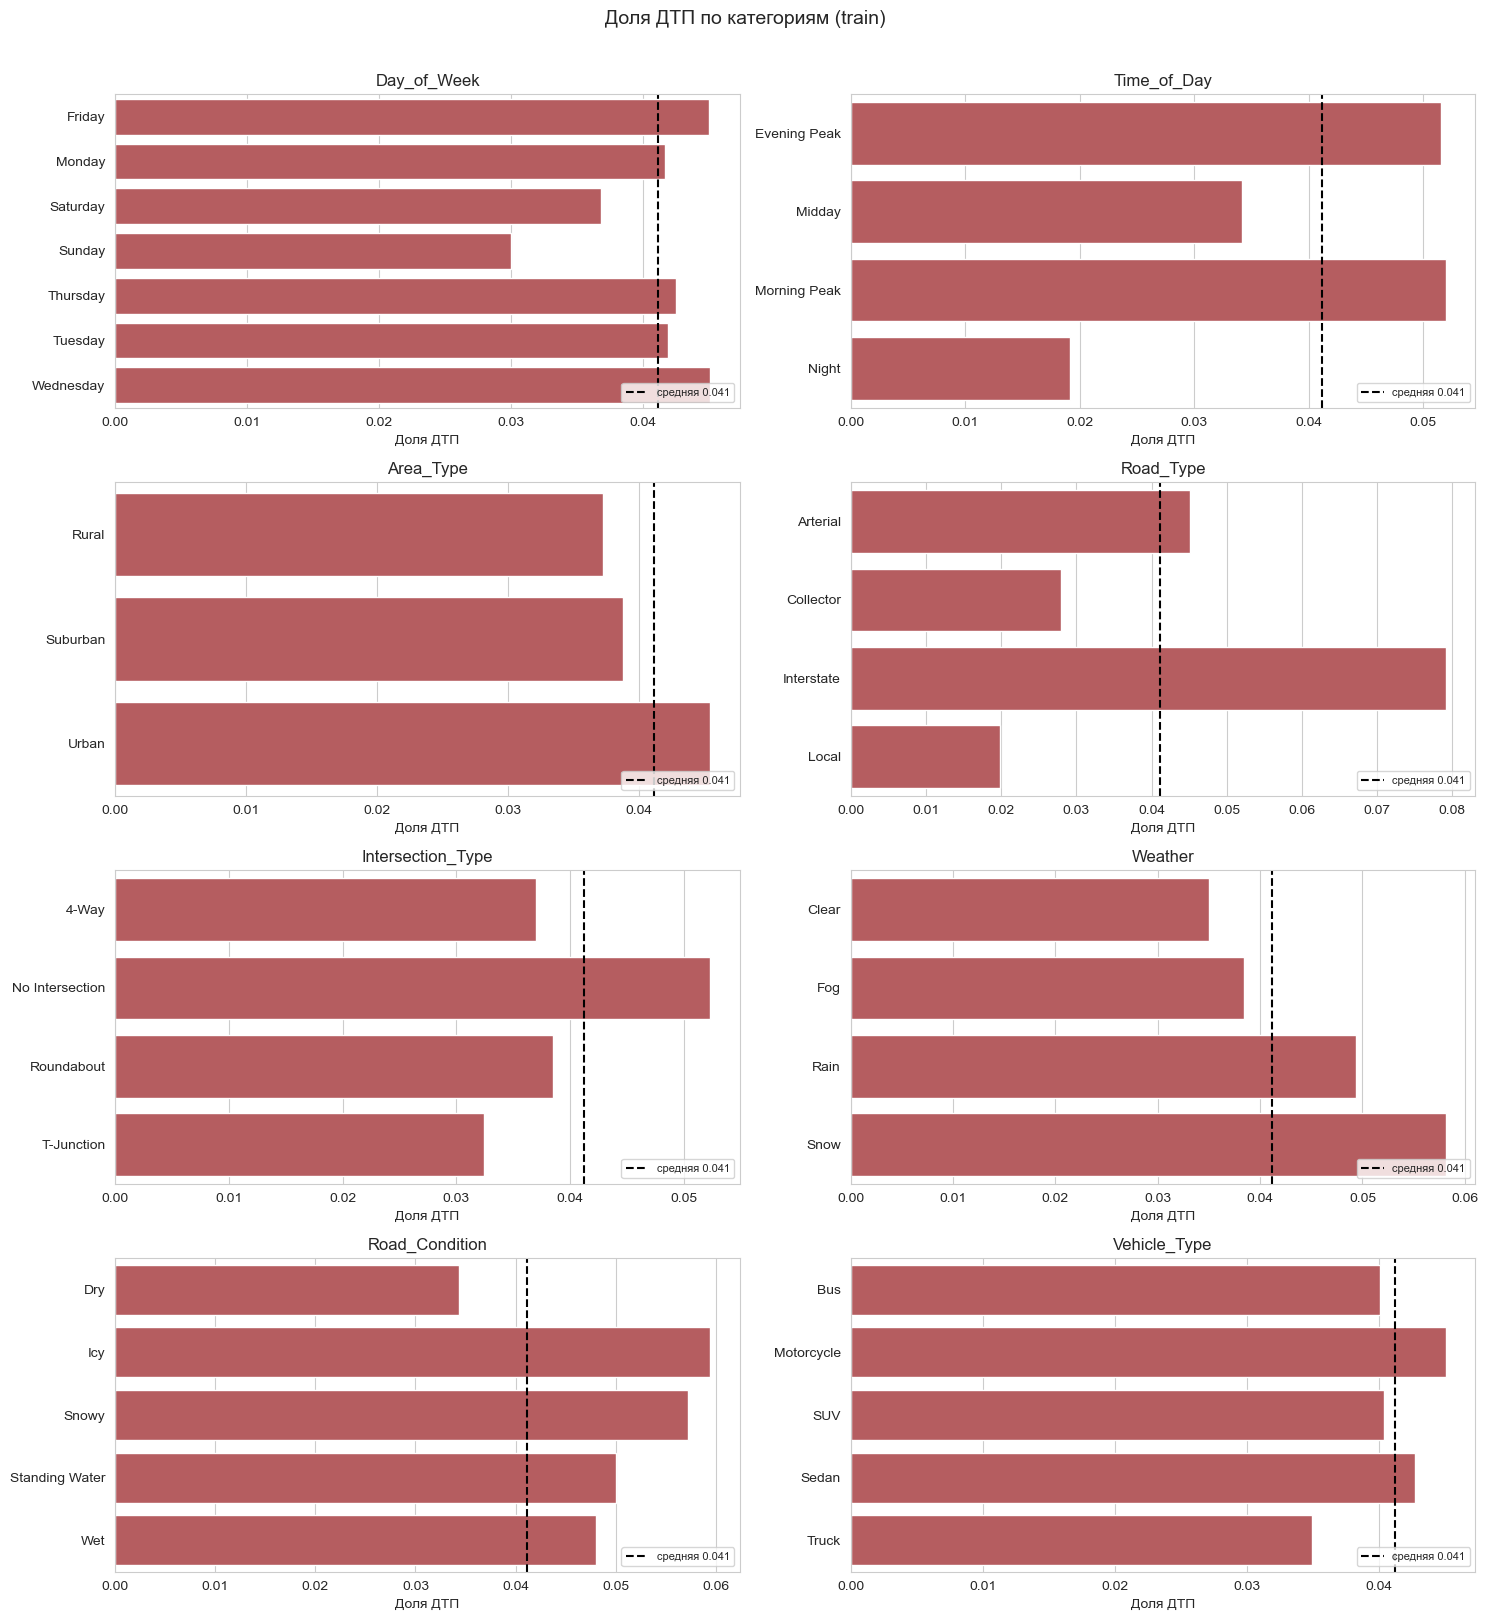

In [30]:
fig, axes = plt.subplots(4, 2, figsize=(15, 16))
axes = axes.ravel()
overall = train_df['Accident_Occurred'].mean()

for ax, col in zip(axes, cat_features):
    rate = train_df.groupby(col, observed=True)['Accident_Occurred'].mean().sort_values(ascending=False)
    sns.barplot(x=rate.values, y=rate.index, ax=ax, color='#C44E52')
    ax.axvline(overall, color='black', linestyle='--', label=f'средняя {overall:.3f}')
    ax.set_title(col)
    ax.set_xlabel('Доля ДТП')
    ax.set_ylabel('')
    ax.legend(loc='lower right', fontsize=8)

plt.suptitle('Доля ДТП по категориям (train)', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

- **Итог:** наиболее информативные категориальные признаки — `Road_Type`, `Time_of_Day`, `Road_Condition`, `Weather`; их стоит в первую очередь проверять на взаимодействия (например, Interstate × Icy × Peak).

### 3.7. Бинарный признак `Is_Holiday`

Отдельно проверим, отличается ли доля ДТП в праздники и обычные дни.

                  mean   count
Обычный день  0.041530  154417
Праздник      0.030754    5105


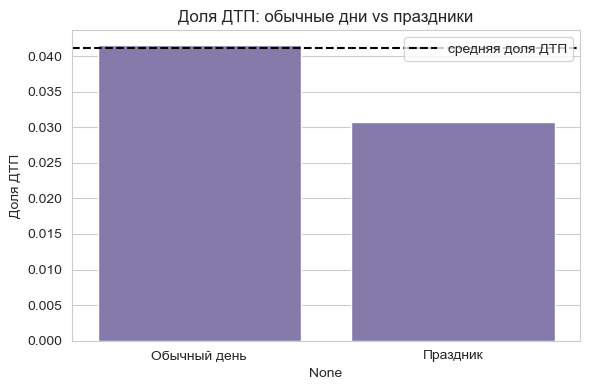

In [31]:
holiday_rate = (
    train_df.groupby('Is_Holiday')['Accident_Occurred']
    .agg(['mean', 'count'])
)
holiday_rate.index = ['Обычный день', 'Праздник']

print(holiday_rate)

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=holiday_rate.index, y=holiday_rate['mean'], ax=ax, color='#8172B2')
ax.axhline(y_train.mean(), color='black', linestyle='--', label='средняя доля ДТП')
ax.set_ylabel('Доля ДТП')
ax.set_title('Доля ДТП: обычные дни vs праздники')
ax.legend()
plt.tight_layout()
plt.show()

**Числа:** в обычные дни доля ДТП = 4.15% (на 154 417 записей), в праздники — 3.08% (на 5 105 записей). Разница ≈ 1 п.п. в пользу обычных дней, средняя доля по выборке — 4.12%.

**Наблюдение.** В праздники аварий **чуть меньше**, а не больше, как можно было бы ожидать. Это может объясняться тем, что в праздники трафик в целом спокойнее (меньше поездок на работу).

**Статистическая значимость.** Разница невелика и на фоне ~5 тыс. наблюдений праздничных дней может быть в пределах случайной вариации. Признак **слабый**, но оставляем его в модели: он бинарный, не мешает kNN и может нести слабый нелинейный сигнал в комбинации с другими признаками.

### 3.8. Корреляционная матрица числовых признаков

Пирсоновская корреляция показывает линейные связи. 

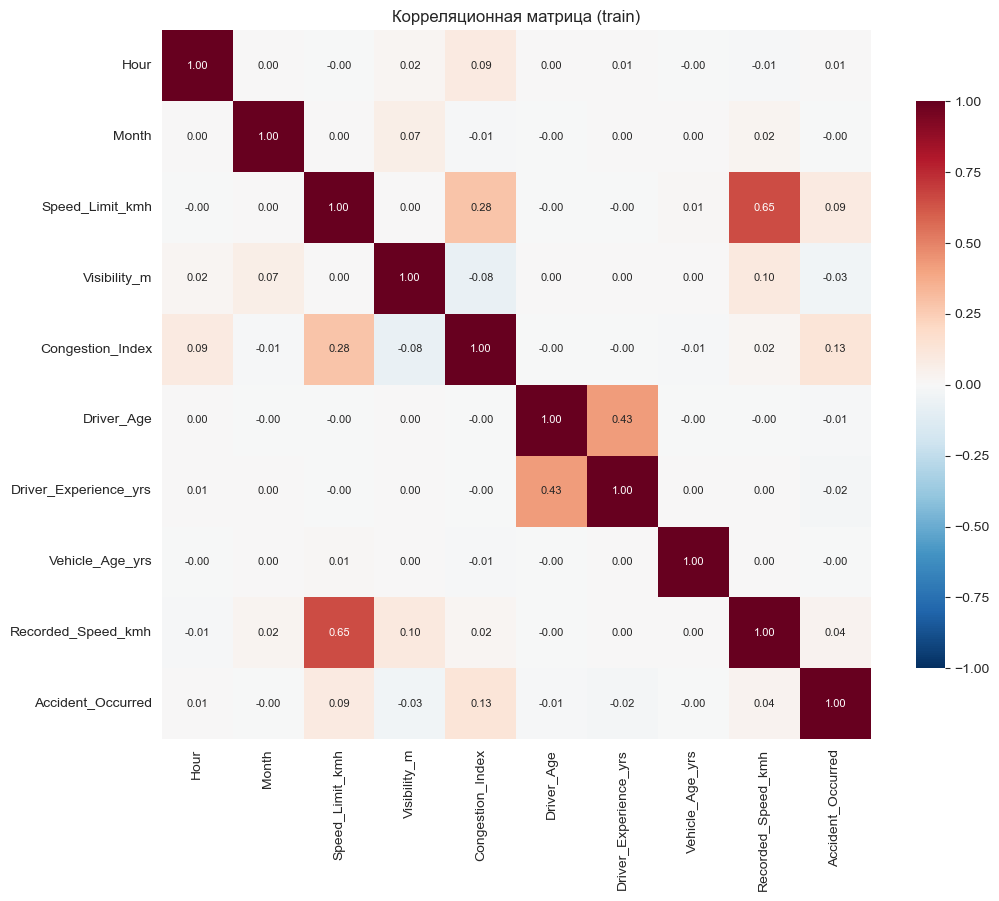

In [32]:
corr_df = train_df[numeric_features + ['Accident_Occurred']].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr_df, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1,
            square=True, cbar_kws={'shrink': 0.8}, annot_kws={'size': 8})
plt.title('Корреляционная матрица (train)')
plt.tight_layout()
plt.show()

In [33]:
corr_df['Accident_Occurred'].drop('Accident_Occurred').sort_values().round(3)

Visibility_m            -0.031
Driver_Experience_yrs   -0.017
Driver_Age              -0.012
Vehicle_Age_yrs         -0.004
Month                   -0.001
Hour                     0.007
Recorded_Speed_kmh       0.036
Speed_Limit_kmh          0.090
Congestion_Index         0.126
Name: Accident_Occurred, dtype: float64

**Вывод.** Линейные корреляции с таргетом слабые (макс. 0.13), значит однофакторная линейная модель не сработает — нужны нелинейные методы (kNN, деревья). При этом сильной мультиколлинеарности нет, все числовые признаки можно оставить. Основной вклад в разделение классов дают **`Congestion_Index`, `Speed_Limit_kmh`, `Visibility_m`, `Recorded_Speed_kmh`**, что совпадает с выводами п. 3.5.

### 3.9. Парные точечные диаграммы (классы разными цветами)

Строим scatter для наиболее содержательных пар признаков. Если точки класса «1» концентрируются в определённой области — kNN сможет их отделить.

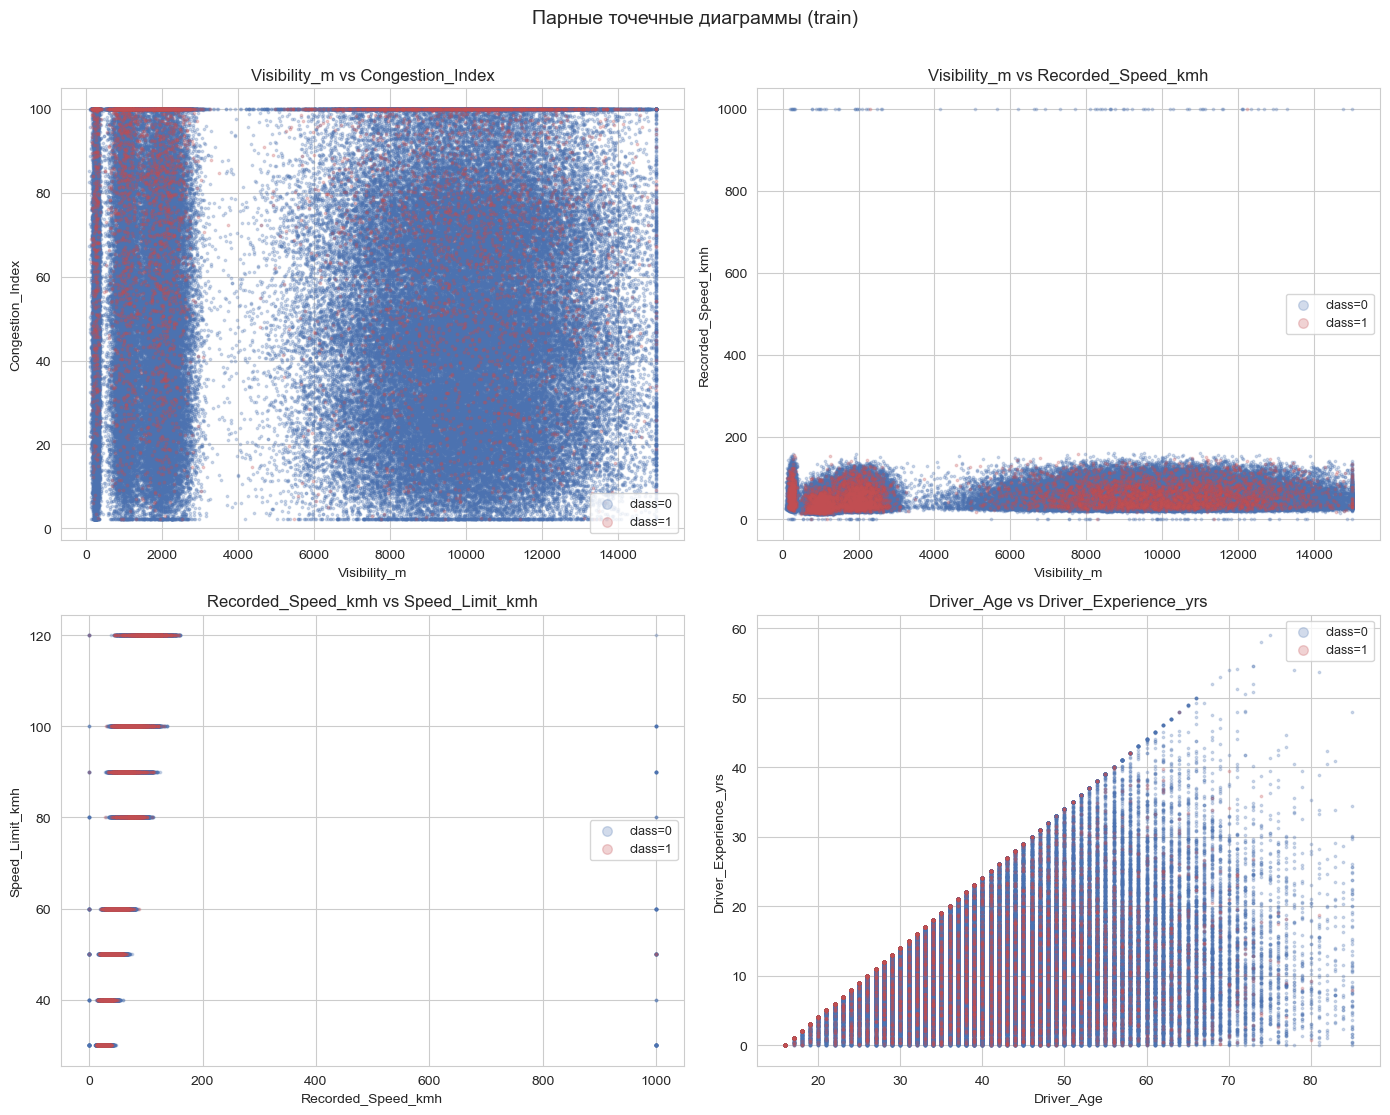

In [34]:
pairs = [
    ('Visibility_m', 'Congestion_Index'),
    ('Visibility_m', 'Recorded_Speed_kmh'),
    ('Recorded_Speed_kmh', 'Speed_Limit_kmh'),
    ('Driver_Age', 'Driver_Experience_yrs'),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.ravel()

for ax, (xcol, ycol) in zip(axes, pairs):
    for label, color in zip([0, 1], ['#4C72B0', '#C44E52']):
        mask = y_train.values == label
        ax.scatter(X_train.loc[mask, xcol], X_train.loc[mask, ycol],
                   s=3, alpha=0.25, color=color, label=f'class={label}')
    ax.set_xlabel(xcol)
    ax.set_ylabel(ycol)
    ax.set_title(f'{xcol} vs {ycol}')
    ax.legend(markerscale=4, fontsize=9)

plt.suptitle('Парные точечные диаграммы (train)', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

### Общие выводы по разделу 3 

- **Дисбаланс классов:** ДТП — **8 213 из 199 403 (4.12%)**, класс «0» — 95.88%

- **Простой линейной связи с фактом ДТП нет:** максимальная корреляция — около 0.13 (`Congestion_Index`), у остальных признаков ещё меньше. Значит, нужны нелинейные модели вроде kNN и деревьев.
- **Признаки почти не дублируют друг друга** — сильной мультиколлинеарности нет, все числовые можно оставить.
- **Самые полезные числовые признаки:** загруженность дороги (`Congestion_Index`) и разрешённая скорость (`Speed_Limit_kmh`); умеренно полезны фактическая скорость и видимость; возраст водителя, стаж и возраст машины почти не влияют.
- **Самые полезные категориальные признаки:** тип дороги (магистрали опаснее локальных), состояние покрытия и погода (лёд, снег, дождь опаснее сухой и ясной погоды), время суток (часы пик опаснее ночи), день недели (будни опаснее воскресенья) и тип зоны (город опаснее села). Тип перекрёстка, тип машины и праздничный день почти не влияют, но их можно оставить — они не мешают.
- **Настоящих выбросов почти нет:** большие значения возраста водителя, стажа и возраста машины — реальные, удалять их не нужно. Артефакт только один — скорость 999 км/ч, её обрежем.
- **Пропуски:** в `Intersection_Type` пропуски означают «перекрёстка нет» — заполним отдельной категорией; в видимости и стаже пропусков мало — заполним медианой/модой.
- **Грязные категории:** в `Weather` один и тот же дождь был записан по-разному (регистр, пробелы) — привели к единому виду.
- **Практический итог:** самые опасные сочетания — магистраль + лёд/снег + высокая скорость + плохая видимость + час пик; самые безопасные — локальная дорога + сухо + ясно + ночь. Поскольку отдельные признаки слабы, польза модели — именно в учёте их совместного влияния.

## 4. Обработка выбросов

### 4.1. Анализ выбросов

В п. 3.3 и 3.4 было показано, что большинство «выбросов» — реальные значения. Единственное исключение — `Recorded_Speed_kmh = 999` (артефакт датчика). Подтвердим:

In [35]:
print(f"Записей с Recorded_Speed_kmh = 999: {(X_train['Recorded_Speed_kmh'] == 999).sum() + (X_test['Recorded_Speed_kmh'] == 999).sum()}")
print(f"Записей со скоростью > 160.8: {(X_train['Recorded_Speed_kmh'] > 160.8).sum() + (X_test['Recorded_Speed_kmh'] > 160.8).sum()}")

Записей с Recorded_Speed_kmh = 999: 104
Записей со скоростью > 160.8: 104


### 4.2. Обоснование подхода

`Recorded_Speed_kmh` связан с `Speed_Limit_kmh`: реальная скорость обычно чуть выше установленного лимита. Заменим артефакты на `Speed_Limit_kmh × 1.1` — это даёт реалистичную оценку скорости с учётом контекста дороги.

### 4.3. Реализация замены

In [36]:
anom_train = X_train['Recorded_Speed_kmh'] > 160.8
anom_test  = X_test['Recorded_Speed_kmh']  > 160.8

X_train.loc[anom_train, 'Recorded_Speed_kmh'] = (
    X_train.loc[anom_train, 'Speed_Limit_kmh'] * 1.1)
X_test.loc[anom_test, 'Recorded_Speed_kmh'] = (
    X_test.loc[anom_test, 'Speed_Limit_kmh'] * 1.1)

print(f"Обработано в train: {anom_train.sum()}, в test: {anom_test.sum()}")

Обработано в train: 82, в test: 22


### 4.4. Визуализация до/после

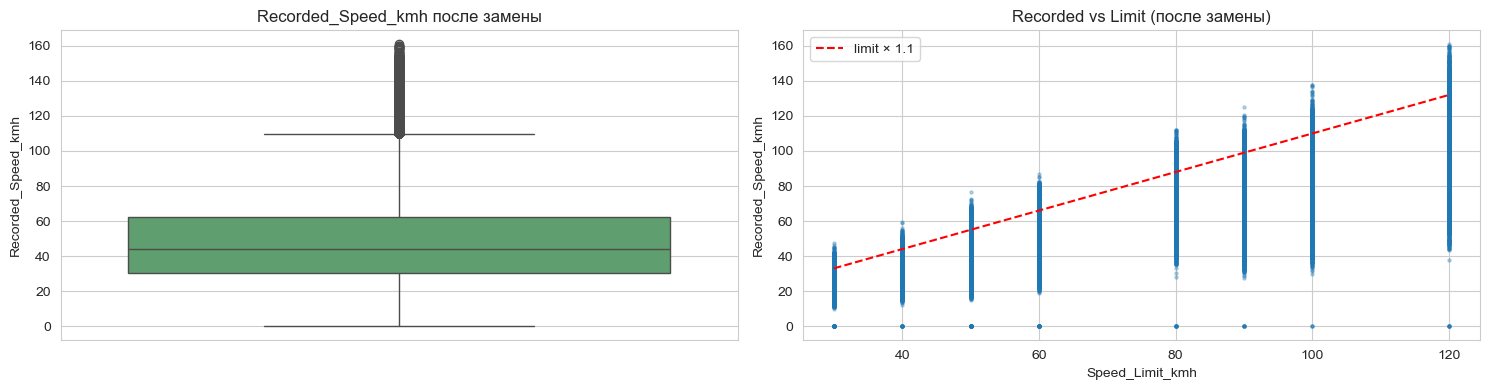

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# Boxplot
sns.boxplot(y=X_train['Recorded_Speed_kmh'], ax=axes[0], color='#55A868')
axes[0].set_title('Recorded_Speed_kmh после замены')

# Scatter: скорость vs лимит
axes[1].scatter(X_train['Speed_Limit_kmh'], X_train['Recorded_Speed_kmh'], s=5, alpha=0.3)
axes[1].plot([30, 120], [30*1.1, 120*1.1], 'r--', label='limit × 1.1')
axes[1].set_xlabel('Speed_Limit_kmh')
axes[1].set_ylabel('Recorded_Speed_kmh')
axes[1].set_title('Recorded vs Limit (после замены)')
axes[1].legend()

plt.tight_layout()
plt.show()

### 4.5. Вывод

Из всех выбросов только `999` в `Recorded_Speed_kmh` — артефакт датчика. Остальные «выбросы» (возраст, стаж, возраст ТС) — реальные и информативные, их не обрабатываем. Артефакты заменены на `Speed_Limit_kmh × 1.1` — это сохраняет строки, учитывает контекст дороги и не создаёт утечки данных.

## 5. Обработка пропущенных значений

### 5.1. Анализ пропусков после предыдущих шагов

`Intersection_Type` уже обработан в п. 1.7 (заполнен `'No Intersection'`). Проверим, что осталось:

In [38]:
missing_train = X_train.isna().sum()
missing_train = missing_train[missing_train > 0].sort_values(ascending=False)
print("Пропуски в train:")
print(missing_train)
print(f"\nПропуски в test:")
print(X_test.isna().sum()[X_test.isna().sum() > 0])

Пропуски в train:
Visibility_m             4080
Driver_Experience_yrs    3176
dtype: int64

Пропуски в test:
Visibility_m             999
Driver_Experience_yrs    810
dtype: int64


### 5.2. Заполнение `Visibility_m` медианой по группам `Weather`

Видимость сильно зависит от погоды, поэтому глобальная медиана исказит данные. Заполним медианой по каждой категории `Weather` (посчитанной на train).

In [39]:
# Медианы видимости по погоде (на train)
vis_medians = X_train.groupby('Weather', observed=True)['Visibility_m'].median()
print(vis_medians)

# Заполнение: маска NaN + map, приведённый к float
for df in (X_train, X_test):
    mask = df['Visibility_m'].isna()
    fill_values = df.loc[mask, 'Weather'].map(vis_medians).astype(float)
    df.loc[mask, 'Visibility_m'] = fill_values

Weather
Clear    10002.4
Fog        250.2
Rain      2002.8
Snow      1000.7
Name: Visibility_m, dtype: float64


### 5.3. Заполнение `Driver_Experience_yrs` медианой по возрастным группам

Глобальная медиана не подходит: `Driver_Age` и `Driver_Experience_yrs` сильно связаны (стаж не может превышать `Driver_Age − 16`). Заполнение глобальной медианой создаст невозможные записи (например, «16 лет, стаж 9 лет»).

Решение: разобьём водителей на возрастные группы, заполним пропуски медианой стажа **внутри каждой группы** и **обрежем сверху** значением `Driver_Age − 16` для каждого конкретного водителя.

In [40]:
# 1. Заполняем пропуски медианой по возрастным группам
age_bins = [15, 21, 26, 36, 51, 100]
age_labels = ['16-20', '21-25', '26-35', '36-50', '51+']

X_train['AgeGroup'] = pd.cut(X_train['Driver_Age'], bins=age_bins, labels=age_labels)
X_test['AgeGroup']  = pd.cut(X_test['Driver_Age'],  bins=age_bins, labels=age_labels)

# Считаем медианы (по train)
exp_medians_by_age = X_train.groupby('AgeGroup', observed=True)['Driver_Experience_yrs'].median()

# Применяем заполнение
for df in (X_train, X_test):
    mask = df['Driver_Experience_yrs'].isna()
    fill_vals = df.loc[mask, 'AgeGroup'].map(exp_medians_by_age).astype(float)
    df.loc[mask, 'Driver_Experience_yrs'] = fill_vals

# 2. Обрезаем стаж сверху для ВСЕХ строк (чтобы не было стажа > возраст - 16)
X_train['Driver_Experience_yrs'] = np.minimum(X_train['Driver_Experience_yrs'], X_train['Driver_Age'] - 16)
X_test['Driver_Experience_yrs']  = np.minimum(X_test['Driver_Experience_yrs'],  X_test['Driver_Age'] - 16)

# 3. Удаляем вспомогательный столбец
X_train = X_train.drop(columns='AgeGroup')
X_test  = X_test.drop(columns='AgeGroup')

# 4. Проверка 
violations_train = (X_train['Driver_Experience_yrs'] > (X_train['Driver_Age'] - 16)).sum()
violations_test  = (X_test['Driver_Experience_yrs']  > (X_test['Driver_Age']  - 16)).sum()

print(f"Нарушений в train: {violations_train}")
print(f"Нарушений в test:  {violations_test}")

assert violations_train == 0 and violations_test == 0
print("Заполнение и проверка пройдены успешно ✓")

Нарушений в train: 0
Нарушений в test:  0
Заполнение и проверка пройдены успешно ✓


### 5.4. Вывод

- `Intersection_Type` — семантические пропуски, обработаны ранее (п. 1.7).
- `Visibility_m` — заполнены медианой по группе `Weather` (учёт контекста).
- `Driver_Experience_yrs` — заполнены медианой **по возрастным группам** с обрезкой сверху по `Driver_Age − 16`. Это учитывает связь между возрастом водителя и стажем и гарантирует физическую корректность.
- Проверка подтверждает: ни у одного водителя стаж не превышает `Driver_Age − 16`, пропусков в данных нет.

## 6. Обработка категориальных признаков

### 6.1. Список категориальных и числовых признаков

Разделяем признаки на категориальные (8 номинальных) и числовые для дальнейшей раздельной обработки.

In [41]:
cat_features = [
    'Day_of_Week', 'Time_of_Day', 'Area_Type', 'Road_Type',
    'Intersection_Type', 'Weather', 'Road_Condition', 'Vehicle_Type',
]
num_features = [c for c in X_train.columns if c not in cat_features]

print(f'Категориальных: {len(cat_features)}')
print(f'Числовых:       {len(num_features)}')

Категориальных: 8
Числовых:       10


### 6.2. OneHotEncoder для категориальных признаков

Кодируем категории в бинарные столбцы с `handle_unknown='ignore'`, чтобы неизвестные в тесте уровни не вызывали ошибку.

In [42]:
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
ohe.fit(X_train[cat_features])

# Считаем общее количество категорий по всем признакам
total_categories = sum(len(cats) for cats in ohe.categories_)
total_encoded_features = ohe.get_feature_names_out(cat_features).size

print(f'Категорий до кодирования:    {total_categories}')
print(f'Признаков после кодирования: {total_encoded_features}')

Категорий до кодирования:    36
Признаков после кодирования: 36


### 6.3. ColumnTransformer: OHE + масштабирование числовых

Объединяем StandardScaler для чисел и OneHotEncoder для категорий в единый препроцессор, обучаемый только на train.

In [43]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features),
    ],
    remainder='drop',
)
print('ColumnTransformer собран')

ColumnTransformer собран


### 6.4. Применение к train и test

Применяем `fit_transform` к train и `transform` к test, проверяем размерности и отсутствие NaN.

In [44]:
X_train_enc = preprocessor.fit_transform(X_train)
X_test_enc  = preprocessor.transform(X_test)

print(f'X_train_enc: {X_train_enc.shape}')
print(f'X_test_enc:  {X_test_enc.shape}')
print(f'NaN в train: {np.isnan(X_train_enc).sum()}')
print(f'NaN в test:  {np.isnan(X_test_enc).sum()}')

X_train_enc: (159522, 46)
X_test_enc:  (39881, 46)
NaN в train: 0
NaN в test:  0


### 6.5. Проверка результата

Смотрим итоговое число признаков после кодирования и первые имена столбцов.

In [45]:
feature_names = preprocessor.get_feature_names_out()
print(f'Всего признаков после обработки: {len(feature_names)}')
print('\nПервые 12 признаков:')
for name in feature_names[:12]:
    print(f'  {name}')

Всего признаков после обработки: 46

Первые 12 признаков:
  num__Hour
  num__Month
  num__Is_Holiday
  num__Speed_Limit_kmh
  num__Visibility_m
  num__Congestion_Index
  num__Driver_Age
  num__Driver_Experience_yrs
  num__Vehicle_Age_yrs
  num__Recorded_Speed_kmh
  cat__Day_of_Week_Friday
  cat__Day_of_Week_Monday


### 6.6. Кодирование категориальных признаков — вывод

Категориальные признаки (`Day_of_Week`, `Time_of_Day`, `Area_Type`, `Road_Type`, `Intersection_Type`, `Weather`, `Road_Condition`, `Vehicle_Type`) являются **номинальными** — внутреннего порядка нет, поэтому числовые коды исказили бы метрику расстояния, критичную для kNN.

Применён **One-Hot Encoding** (`OneHotEncoder` в `ColumnTransformer`, `handle_unknown='ignore'`):
- не вносит ложной иерархии между уровнями;
- бинарные индикаторы после нормализации равноправны в евклидовой метрике;
- размерность растёт умеренно (36 уровней суммарно);
- устойчив к неизвестным уровням в тесте.

Энкодер обучается **только на `X_train`** внутри `Pipeline` и применяется к `X_test` в обученном виде — утечки данных нет.

## 7. Нормализация

### 7.1. Постановка задачи нормализации

kNN использует евклидову метрику, чувствительную к масштабу признаков. Числовые признаки имеют разные диапазоны (`Visibility_m` ~ 10⁴, `Driver_Age` ~ 10¹), поэтому без нормализации доминировать будет `Visibility_m`. Нормализация **обязательна**.

In [49]:
print("Числовые признаки (масштабируются):", num_features)
print("Категориальные (One-Hot, без масштабирования):", cat_features)
print(X_train[num_features].describe().T[['min', 'max', 'std']].round(2))

Числовые признаки (масштабируются): ['Hour', 'Month', 'Is_Holiday', 'Speed_Limit_kmh', 'Visibility_m', 'Congestion_Index', 'Driver_Age', 'Driver_Experience_yrs', 'Vehicle_Age_yrs', 'Recorded_Speed_kmh']
Категориальные (One-Hot, без масштабирования): ['Day_of_Week', 'Time_of_Day', 'Area_Type', 'Road_Type', 'Intersection_Type', 'Weather', 'Road_Condition', 'Vehicle_Type']
                        min       max      std
Hour                    0.0     23.00     5.51
Month                   1.0     12.00     3.45
Is_Holiday              0.0      1.00     0.18
Speed_Limit_kmh        30.0    120.00    26.38
Visibility_m           73.2  15000.00  4555.15
Congestion_Index        2.2    100.00    28.70
Driver_Age             16.0     85.00    13.28
Driver_Experience_yrs   0.0     59.00     7.75
Vehicle_Age_yrs         0.0     30.00     4.77
Recorded_Speed_kmh      0.0    160.74    23.47


### 7.2. Выбор метода — StandardScaler

`StandardScaler` (z-нормализация: `(x−μ)/σ`) устойчив к выбросам в отличие от `MinMaxScaler` и даёт нулевое среднее и единичную дисперсию — оптимально для kNN и линейных моделей. Метод уже применён внутри `preprocessor` (п.6), отдельный вызов не нужен.

In [50]:
print("Трансформеры в preprocessor:")
for name, trans, cols in preprocessor.transformers_:
    n = len(cols) if isinstance(cols, list) else '?'
    print(f"  {name}: {type(trans).__name__} → {n} признаков")

Трансформеры в preprocessor:
  num: StandardScaler → 10 признаков
  cat: OneHotEncoder → 8 признаков


### 7.3. Объединение со закодированными категориальными признаками

`ColumnTransformer` уже собрал итоговые матрицы: нормализованные числовые + One-Hot категориальные (из п.6). Достаточно переиспользовать `X_train_enc` / `X_test_enc` и проверить свойства.

In [51]:
X_train_processed = X_train_enc
X_test_processed  = X_test_enc

print(f"X_train_processed: {X_train_processed.shape}")
print(f"X_test_processed:  {X_test_processed.shape}")

num_block = X_train_processed[:, :len(num_features)]
print(f"μ числового блока (train): {num_block.mean(axis=0).round(4)}")
print(f"σ числового блока (train): {num_block.std(axis=0).round(4)}")
print(f"NaN в train: {np.isnan(X_train_processed).sum()}, NaN в test: {np.isnan(X_test_processed).sum()}")
print(f"Среднее по признакам (train): {X_train_processed.mean(axis=0).round(3)[:5]} ...")

X_train_processed: (159522, 46)
X_test_processed:  (39881, 46)
μ числового блока (train): [-0. -0.  0.  0. -0. -0.  0.  0. -0.  0.]
σ числового блока (train): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
NaN в train: 0, NaN в test: 0
Среднее по признакам (train): [-0. -0.  0.  0. -0.] ...


### 7.4. Вывод

- Нормализация **необходима**: разброс признаков отличается на 3–4 порядка.
- Применён `StandardScaler` (внутри `ColumnTransformer` из п.6) — устойчив к выбросам, даёт μ≈0, σ≈1.
- `fit` выполнен **только на `X_train`**, `transform` применён к `X_test` → утечки нет.
- Итоговые матрицы `X_train_processed` и `X_test_processed` готовы для kNN.